In [1]:
!pip install transformers gradio pillow -q

In [4]:
from transformers import BlipProcessor, BlipForConditionalGeneration

# Load the BLIP processor and model directly to avoid generic auto-class import issues
processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base")

print("AI Image Caption Model and Processor Loaded Successfully!")

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

AI Image Caption Model and Processor Loaded Successfully!


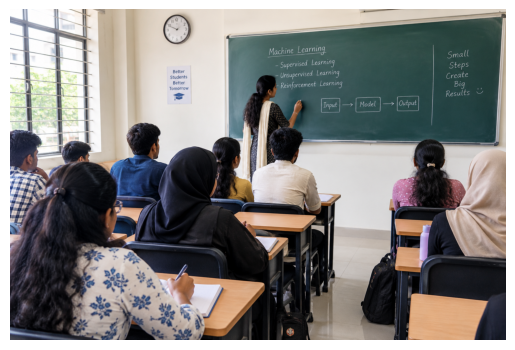

Image size: (1536, 1024)


In [6]:
from PIL import Image
import matplotlib.pyplot as plt

# Load the image with the corrected string syntax
image_path = "/content/Machine Learning Classroom in Session.png"
image = Image.open(image_path).convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.show()

print("Image size:", image.size)

In [8]:
# Prepare the image for the model
inputs = processor(images=image, return_tensors="pt")

# Generate the caption
outputs = model.generate(**inputs, max_new_tokens=50)

# Decode and display the result
caption = processor.decode(outputs[0], skip_special_tokens=True)
print("Generated Caption:", caption)

Generated Caption: a blackboard on the wall


In [12]:
import gradio as gr

def generate_caption(img):
    raw_image = img.convert("RGB")
    inputs = processor(images=raw_image, return_tensors="pt")
    outputs = model.generate(**inputs, max_new_tokens=50)
    caption = processor.decode(outputs[0], skip_special_tokens=True)
    return caption

# Clean modern dark theme CSS
custom_css = """
body, .gradio-container {
    background: #0f172a !important;
    color: #f8fafc !important;
}
.gradio-container h1, .gradio-container p {
    color: #f8fafc !important;
}
.block {
    background: #1e293b !important;
    border: 1px solid #334155 !important;
    border-radius: 12px !important;
}
button.primary {
    background: linear-gradient(135deg, #6366f1, #a855f7) !important;
    border: none !important;
    color: white !important;
}
"""

demo = gr.Interface(
    fn=generate_caption,
    inputs=gr.Image(type="pil", label="Upload an Image"),
    outputs=gr.Textbox(label="Generated Caption"),
    title="AI Image Caption Generator",
    description="Upload any image and let AI describe it."
)

demo.launch(share=True, css=custom_css)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b6009d7c41d37b45aa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
